# Reproducing "IoT Network Intrusion Detection Using Machine Learning on UNSW-NB15 Dataset"

**Paper:** Omarov et al., _Herald of the Kazakh-British Technical University_, No. 3(70), 2024. DOI: 10.55452/1998-6688-2024-21-3-48-57

This notebook runs one experiment, following the paper's Figure 1 and Equations 3-6. Choose **Runtime > Run all**. You don't need a GPU.

**Taken from the paper**

- UNSW-NB15 dataset, binary task (normal vs. attack)
- Remove infinite, none and symbol values, then normalize
- KNN, Naive Bayes, Decision Tree, SVM, Logistic Regression, AdaBoost, Random Forest
- Accuracy, precision, recall and F1 from Equations 3-6, ROC-AUC, error matrix, execution time

**Not in the paper, but the code can't run without a choice**

| Missing detail                             | Choice                                       | Why this one                             |
| ------------------------------------------ | -------------------------------------------- | ---------------------------------------- |
| Train/test split                           | The dataset's own training and testing files | UNSW's split, not one we invented        |
| Text columns (`proto`, `service`, `state`) | One-hot encoding                             | The models only accept numbers           |
| Normalization formula                      | Min-max                                      | The usual meaning of normalization       |
| Hyperparameters                            | scikit-learn defaults, with nothing tuned    | No values of our own                     |
| Positive class                             | Attack                                       | The paper's task is detecting intrusions |
| Random seed                                | 42                                           | Needed for repeatable runs               |

**Before you rely on this notebook**

- This version has only had a Python syntax check. It reuses code from the earlier run, but it hasn't been run itself.
- The paper's exact numbers can't be guaranteed, because of the missing details above.
- This notebook is AI-generated. Your professor's policy covers AI-generated content, so ask whether AI-assisted code is allowed, and write the report yourselves.


## 1. Settings and setup

- `DATA_SOURCE`: `"drive"` finds the two CSV files anywhere in your Google Drive. `"upload"` asks you to select them.
- `USE_DRIVE`: `True` saves results to Google Drive, so they survive a Colab disconnect.

Results are reused if you re-run the notebook. To start again, delete the files in the results folder.


In [5]:
DATA_SOURCE = "upload"
USE_DRIVE = False
SEED = 42

import gc
import platform
import shutil
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

if DATA_SOURCE == "drive" or USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
# Results get their own folder, so the zip in Section 7 doesn't include the dataset.
OUT = Path("/content/drive/MyDrive/unsw_nb15_reproduction/paper_method") if USE_DRIVE else Path("results")
OUT.mkdir(parents=True, exist_ok=True)

versions = {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
            "pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__}
pd.Series(versions).to_csv(OUT / "versions.csv", header=False)
print(versions)
print("Results folder:", OUT.resolve())

{'python': '3.13.18', 'scikit-learn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.4.6', 'matplotlib': '3.10.0'}
Results folder: /content/results


## 2. Import the dataset

The paper only says "UNSW-NB15". This notebook uses the dataset's own training and testing files.


In [6]:
TRAIN_FILE = "UNSW_NB15_training-set.csv"
TEST_FILE = "UNSW_NB15_testing-set.csv"

# Check if files exist in the main /content directory first, and move them to data/ if needed
for name in (TRAIN_FILE, TEST_FILE):
    local_file = Path(f"/content/{name}")
    if local_file.exists():
        print(f"Found {name} in /content. Moving to {DATA_DIR / name}")
        shutil.move(str(local_file), DATA_DIR / name)

if not (DATA_DIR / TRAIN_FILE).exists() or not (DATA_DIR / TEST_FILE).exists():
    if DATA_SOURCE == "drive":
        for name in (TRAIN_FILE, TEST_FILE):
            found = list(Path("/content/drive/MyDrive").glob(f"**/{name}"))
            if not found:
                raise FileNotFoundError(f"Could not find {name} in your Google Drive")
            print("Copying", found[0])
            shutil.copy(found[0], DATA_DIR / name)
    elif DATA_SOURCE == "upload":
        from google.colab import files
        print(f"Select {TRAIN_FILE} and {TEST_FILE}")
        for name, content in files.upload().items():
            (DATA_DIR / name).write_bytes(content)
    else:
        raise ValueError('DATA_SOURCE must be "drive" or "upload"')

# utf-8-sig: the CSV headers start with a byte-order mark
raw_train = pd.read_csv(DATA_DIR / TRAIN_FILE, encoding="utf-8-sig")
raw_test = pd.read_csv(DATA_DIR / TEST_FILE, encoding="utf-8-sig")

# Stop early if these aren't the expected files.
assert raw_train.shape == (175341, 45), f"unexpected training shape {raw_train.shape}"
assert raw_test.shape == (82332, 45), f"unexpected testing shape {raw_test.shape}"
assert list(raw_train.columns) == list(raw_test.columns), "training and testing columns differ"
print("Dataset verified:", raw_train.shape, raw_test.shape)
raw_train.head()

Dataset verified: (175341, 45) (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


## 3. Data preprocessing (Figure 1, Phase B)

| Step | Action                                                             | Source                                         |
| ---- | ------------------------------------------------------------------ | ---------------------------------------------- |
| 3.1  | Remove infinite values                                             | Figure 1                                       |
| 3.2  | Remove none values                                                 | Figure 1                                       |
| 3.3  | Remove symbol values, meaning text values with no letter or digit  | Figure 1, whose wording is all the paper gives |
| 3.4  | Separate the features from `label`, and drop `id` and `attack_cat` | Figure 1 "Data Classification", as interpreted |
| 3.5  | One-hot encode text columns                                        | Required by the models, not in the paper       |
| 3.6  | Min-max normalize numeric columns                                  | Figure 1, formula assumed                      |

The encoder and scaler are fitted on the training data only.

In the earlier run, `"-"` in `service` was the only symbol found, and removing it left 81,173 training rows and 35,179 testing rows with 58 encoded features. Check that this run agrees, and record the numbers. This removes more than half of the data, because that's what the literal wording of Figure 1 does.


In [7]:
CATEGORICAL = ["proto", "service", "state"]
DROP = ["id", "attack_cat", "label"]
NUMERIC = [c for c in raw_train.columns if c not in CATEGORICAL + DROP]


def clean(df):
    counts = {"rows before": len(df)}
    df = df.copy()

    # 3.1 Infinite values
    is_infinite = np.isinf(df[NUMERIC]).any(axis=1)
    counts["infinite"] = int(is_infinite.sum())
    df = df[~is_infinite]

    # 3.2 None values, either missing or written as the text "none"
    is_none = df.isna().any(axis=1) | df[CATEGORICAL].apply(lambda c: c.str.lower().eq("none")).any(axis=1)
    counts["none"] = int(is_none.sum())
    df = df[~is_none]

    # 3.3 Symbol values, such as "-"
    is_symbol = df[CATEGORICAL].apply(lambda c: c.str.fullmatch(r"[^0-9A-Za-z]+")).any(axis=1)
    counts["symbol"] = int(is_symbol.sum())
    df = df[~is_symbol]

    counts["rows after"] = len(df)
    return df, counts


train_df, train_counts = clean(raw_train)
test_df, test_counts = clean(raw_test)
display(pd.DataFrame({"train": train_counts, "test": test_counts}))

# 3.4 Separate features and target
X_train_raw, y_train = train_df.drop(columns=DROP), train_df["label"].to_numpy()
X_test_raw, y_test = test_df.drop(columns=DROP), test_df["label"].to_numpy()

# 3.5 and 3.6 Encode and normalize
prep = ColumnTransformer([
    ("num", MinMaxScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
X_train = prep.fit_transform(X_train_raw)
X_test = prep.transform(X_test_raw)
print("Train:", X_train.shape, "Test:", X_test.shape)
print(f"Attack share: train {100 * y_train.mean():.2f}%, test {100 * y_test.mean():.2f}%")

,train,test
rows before,175341,82332
infinite,0,0
none,0,0
symbol,94168,47153
rows after,81173,35179


Train: (81173, 58) Test: (35179, 58)
Attack share: train 75.99%, test 72.64%


## 4. Train and test the models (Figure 1, Phases C and D)

All seven use scikit-learn's default settings, on all of the cleaned training rows. If Logistic Regression shows a `ConvergenceWarning`, leave the setting as it is and report the warning.

Metrics follow Equations 3-6, with attack as the positive class:

- Accuracy = (TP + TN) / (P + N)
- Precision = TP / (TP + FP)
- Recall = TP / (TP + FN)
- F1 = 2 x Precision x Recall / (Precision + Recall)

The paper also describes ROC-AUC and the error matrix, and Figure 1 lists execution time, so these are recorded too. The paper doesn't report their values, so they have nothing to compare against.

SVM and KNN are the slowest. Times depend on Colab's hardware.


In [8]:
PAPER = pd.DataFrame(
    [("KNN", 86.03, 86.12, 86.02, 86.02),
     ("Naive Bayes", 83.05, 83.79, 83.09, 83.47),
     ("Decision Tree", 82.27, 82.34, 82.19, 82.31),
     ("SVM", 87.21, 87.18, 87.80, 87.18),
     ("Logistic Regression", 86.08, 86.54, 86.85, 86.48),
     ("AdaBoost", 87.54, 87.24, 87.31, 87.60),
     ("Random Forest", 87.82, 87.85, 87.84, 87.65)],
    columns=["model", "accuracy", "precision", "recall", "f1"]).set_index("model")
MODEL_ORDER = list(PAPER.index)

MODELS = {
    "KNN": lambda: KNeighborsClassifier(n_jobs=-1),
    "Naive Bayes": GaussianNB,
    "Decision Tree": lambda: DecisionTreeClassifier(random_state=SEED),
    "SVM": lambda: SVC(random_state=SEED),
    "Logistic Regression": lambda: LogisticRegression(random_state=SEED),
    "AdaBoost": lambda: AdaBoostClassifier(random_state=SEED),
    "Random Forest": lambda: RandomForestClassifier(n_jobs=-1, random_state=SEED),
}

RESULTS_FILE = OUT / "results.csv"
rows = pd.read_csv(RESULTS_FILE).to_dict("records") if RESULTS_FILE.exists() else []
finished = {r["model"] for r in rows}
if finished:
    print("Already finished, not re-running:", sorted(finished))


def scores_path(name):
    return OUT / f"scores_{name.replace(' ', '_')}.npz"


for name in MODEL_ORDER:
    if name in finished:
        continue
    print(f"{name}: training on {len(y_train):,} rows...", flush=True)
    model = MODELS[name]()
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    if name == "KNN":
        # Prediction and ROC-AUC share one neighbour search, because it's slow.
        score = model.predict_proba(X_test)[:, 1]
        pred = (score > 0.5).astype(int)
    else:
        pred = model.predict(X_test)
    predict_seconds = time.perf_counter() - start
    if name != "KNN":
        score = model.decision_function(X_test) if name == "SVM" else model.predict_proba(X_test)[:, 1]

    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        "model": name,
        "accuracy": 100 * accuracy_score(y_test, pred),
        "precision": 100 * precision, "recall": 100 * recall, "f1": 100 * f1,
        "roc_auc": roc_auc_score(y_test, score),
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    })
    # Save after every model, so a disconnect loses only the model in progress.
    pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)
    np.savez_compressed(scores_path(name), y=y_test, score=score)
    print(f"  accuracy={rows[-1]['accuracy']:.2f} precision={rows[-1]['precision']:.2f} recall={rows[-1]['recall']:.2f} "
          f"f1={rows[-1]['f1']:.2f} auc={rows[-1]['roc_auc']:.3f} fit={fit_seconds:.1f}s predict={predict_seconds:.1f}s", flush=True)
    del model
    gc.collect()

results = pd.DataFrame(rows).set_index("model").loc[MODEL_ORDER]

KNN: training on 81,173 rows...
  accuracy=93.99 precision=92.78 recall=99.46 f1=96.01 auc=0.965 fit=0.0s predict=28.0s
Naive Bayes: training on 81,173 rows...
  accuracy=81.20 precision=98.72 recall=75.08 f1=85.30 auc=0.941 fit=0.1s predict=0.1s
Decision Tree: training on 81,173 rows...
  accuracy=94.43 precision=93.71 recall=98.98 f1=96.27 auc=0.907 fit=1.7s predict=0.0s
SVM: training on 81,173 rows...
  accuracy=92.04 precision=90.12 recall=100.00 f1=94.81 auc=0.991 fit=41.6s predict=14.3s
Logistic Regression: training on 81,173 rows...
  accuracy=91.55 precision=90.10 recall=99.27 f1=94.47 auc=0.990 fit=1.2s predict=0.0s
AdaBoost: training on 81,173 rows...
  accuracy=94.80 precision=93.82 recall=99.39 f1=96.52 auc=0.997 fit=13.7s predict=0.3s
Random Forest: training on 81,173 rows...
  accuracy=95.33 precision=94.27 recall=99.64 f1=96.88 auc=0.997 fit=10.2s predict=0.2s


## 5. Compare with the paper

### 5.1 Table 1 vs. our results

A positive gap means our score is higher than the paper's.


In [9]:
comparison = pd.DataFrame(index=MODEL_ORDER)
for metric in ("accuracy", "precision", "recall", "f1"):
    comparison[f"{metric}_paper"] = PAPER[metric]
    comparison[f"{metric}_ours"] = results[metric]
    comparison[f"{metric}_gap"] = results[metric] - PAPER[metric]
comparison = comparison.round(2)
comparison.to_csv(OUT / "comparison.csv")
comparison

,accuracy_paper,accuracy_ours,accuracy_gap,precision_paper,precision_ours,precision_gap,recall_paper,recall_ours,recall_gap,f1_paper,f1_ours,f1_gap
KNN,86.03,93.99,7.96,86.12,92.78,6.66,86.02,99.46,13.44,86.02,96.01,9.99
Naive Bayes,83.05,81.20,-1.85,83.79,98.72,14.93,83.09,75.08,-8.01,83.47,85.30,1.83
Decision Tree,82.27,94.43,12.16,82.34,93.71,11.37,82.19,98.98,16.79,82.31,96.27,13.96
SVM,87.21,92.04,4.83,87.18,90.12,2.94,87.80,100.00,12.20,87.18,94.81,7.63
Logistic Regression,86.08,91.55,5.47,86.54,90.10,3.56,86.85,99.27,12.42,86.48,94.47,7.99
AdaBoost,87.54,94.80,7.26,87.24,93.82,6.58,87.31,99.39,12.08,87.60,96.52,8.92
Random Forest,87.82,95.33,7.51,87.85,94.27,6.42,87.84,99.64,11.80,87.65,96.88,9.23


### 5.2 Model ranking and the paper's main claim

The paper's conclusion is that Random Forest is best, with AdaBoost close behind, and that Naive Bayes and Decision Tree are weakest.


In [10]:
ranking = pd.DataFrame({
    "paper": PAPER["accuracy"].sort_values(ascending=False).index,
    "ours": results["accuracy"].sort_values(ascending=False).index,
}, index=range(1, len(MODEL_ORDER) + 1))
ranking.to_csv(OUT / "ranking.csv")
display(ranking)
print("Largest accuracy gap:", round((results["accuracy"] - PAPER["accuracy"]).abs().max(), 2), "points")
print("Models within 0.01 of the paper on all four metrics:",
      int(((results[["accuracy", "precision", "recall", "f1"]] - PAPER).abs() <= 0.01).all(axis=1).sum()), "of 7")

,paper,ours
1,Random Forest,Random Forest
2,AdaBoost,AdaBoost
3,SVM,Decision Tree
4,Logistic Regression,KNN
5,KNN,SVM
6,Naive Bayes,Logistic Regression
7,Decision Tree,Naive Bayes


Largest accuracy gap: 12.16 points
Models within 0.01 of the paper on all four metrics: 0 of 7


### 5.3 Does Table 1 agree with the paper's own Equation 6?

Equation 6 defines F1 from precision and recall, so the paper's F-score can be recalculated from its own table. This uses only the paper's numbers. Table 1 is rounded to 2 decimals, so a difference above about 0.01 can't be explained by rounding.


In [11]:
equation_check = PAPER[["precision", "recall", "f1"]].copy()
equation_check["f1_from_equation_6"] = 2 * PAPER["precision"] * PAPER["recall"] / (PAPER["precision"] + PAPER["recall"])
equation_check["difference"] = equation_check["f1"] - equation_check["f1_from_equation_6"]
equation_check["explained_by_rounding"] = equation_check["difference"].abs() <= 0.01
equation_check.round(2)

,precision,recall,f1,f1_from_equation_6,difference,explained_by_rounding
model,,,,,,
KNN,86.12,86.02,86.02,86.07,-0.05,False
Naive Bayes,83.79,83.09,83.47,83.44,0.03,False
Decision Tree,82.34,82.19,82.31,82.26,0.05,False
SVM,87.18,87.80,87.18,87.49,-0.31,False
Logistic Regression,86.54,86.85,86.48,86.69,-0.21,False
AdaBoost,87.24,87.31,87.60,87.27,0.33,False
Random Forest,87.85,87.84,87.65,87.84,-0.19,False


### 5.4 Charts


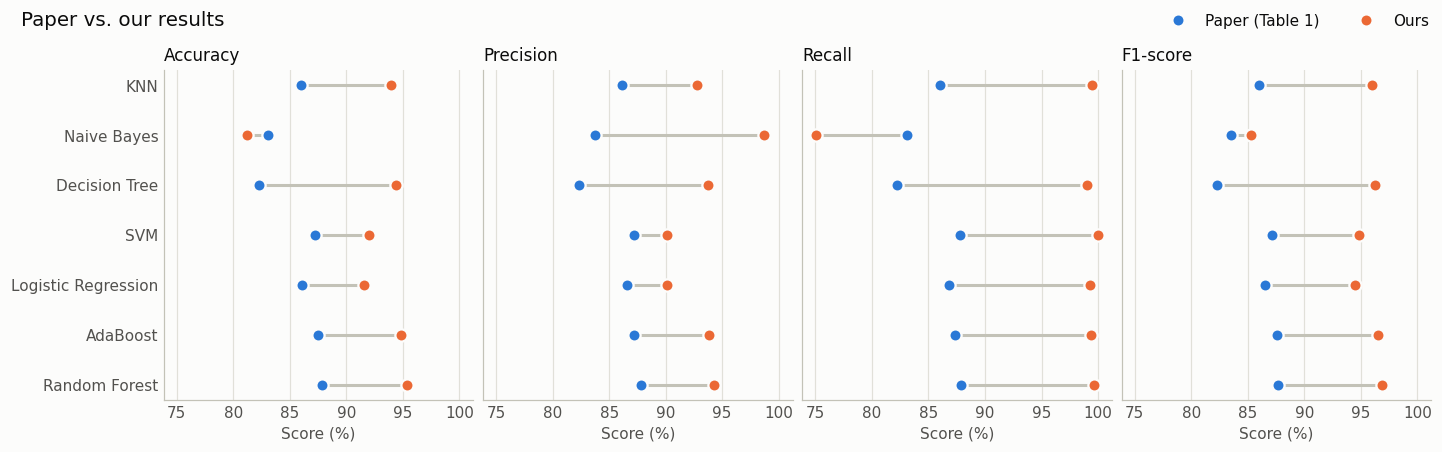

In [12]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
SURFACE, INK, INK_2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 200,
})

# Paper vs. ours for each metric (Table 1 and Figure 2). Dots allow a zoomed axis, which bars wouldn't.
y = np.arange(len(MODEL_ORDER))
fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharey=True, sharex=True, constrained_layout=True)
for ax, metric in zip(axes, ("accuracy", "precision", "recall", "f1")):
    ax.hlines(y, PAPER[metric], results[metric], color=AXIS, linewidth=2, zorder=1)
    ax.plot(PAPER[metric], y, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Paper (Table 1)", zorder=2)
    ax.plot(results[metric], y, "o", color=ORANGE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Ours", zorder=3)
    ax.set_title("F1-score" if metric == "f1" else metric.capitalize(), loc="left", fontsize=11)
    ax.set_xlabel("Score (%)")
    ax.grid(axis="x")
    ax.tick_params(length=0)
axes[0].set_yticks(y, MODEL_ORDER)
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper right", ncols=2, frameon=False)
fig.suptitle("Paper vs. our results", x=0.01, ha="left", fontsize=13)
fig.savefig(OUT / "paper_vs_ours.png")
plt.show()

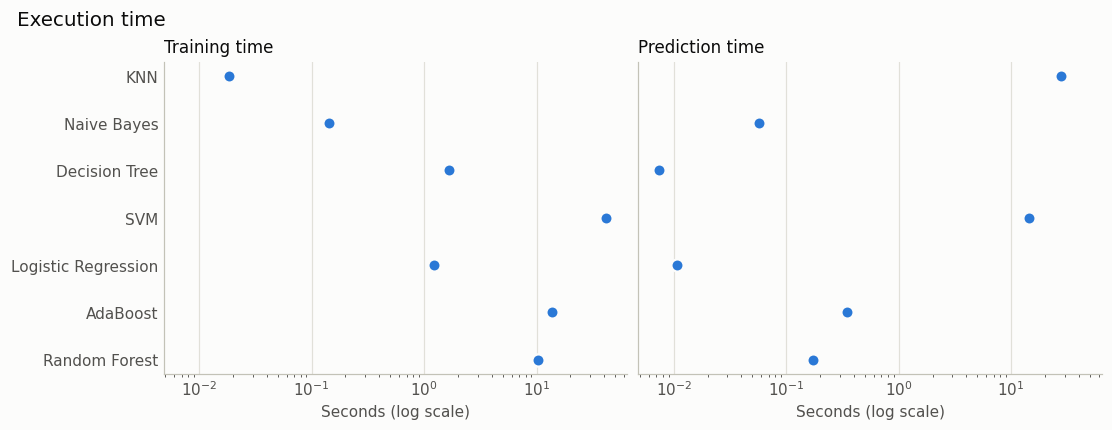

In [13]:
# Execution time. Log scale, because the models differ by orders of magnitude.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, sharex=True, constrained_layout=True)
for ax, (col, title) in zip(axes, [("fit_seconds", "Training time"), ("predict_seconds", "Prediction time")]):
    ax.plot(results[col], y, "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.set_xscale("log")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Seconds (log scale)")
    ax.grid(axis="x")
    ax.tick_params(length=0)
axes[0].set_yticks(y, MODEL_ORDER)
axes[0].invert_yaxis()
fig.suptitle("Execution time", x=0.01, ha="left", fontsize=13)
fig.savefig(OUT / "execution_time.png")
plt.show()

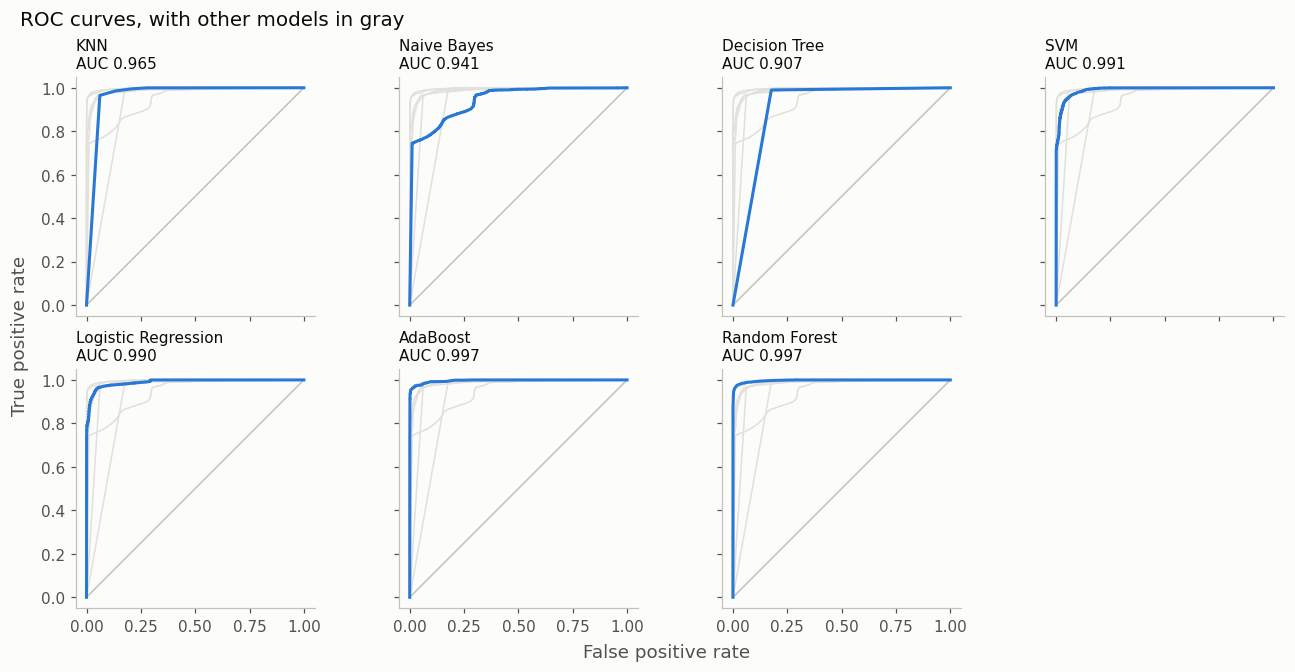

In [14]:
# ROC curves, one panel per model, because seven overlapping colors can't be told apart.
curves = {}
for name in MODEL_ORDER:
    stored = np.load(scores_path(name))
    fpr, tpr, _ = roc_curve(stored["y"], stored["score"])
    curves[name] = (fpr, tpr)

fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True, constrained_layout=True)
axes = axes.ravel()
for ax, name in zip(axes, MODEL_ORDER):
    ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
    for other, (fpr, tpr) in curves.items():
        if other != name:
            ax.plot(fpr, tpr, color=GRID, linewidth=1)
    ax.plot(*curves[name], color=BLUE, linewidth=2)
    ax.set_title(f"{name}\nAUC {results.loc[name, 'roc_auc']:.3f}", loc="left", fontsize=10)
    ax.set_aspect("equal")
axes[-1].set_visible(False)
fig.supxlabel("False positive rate", color=INK_2)
fig.supylabel("True positive rate", color=INK_2)
fig.suptitle("ROC curves, with other models in gray", x=0.01, ha="left", fontsize=13)
fig.savefig(OUT / "roc_curves.png")
plt.show()

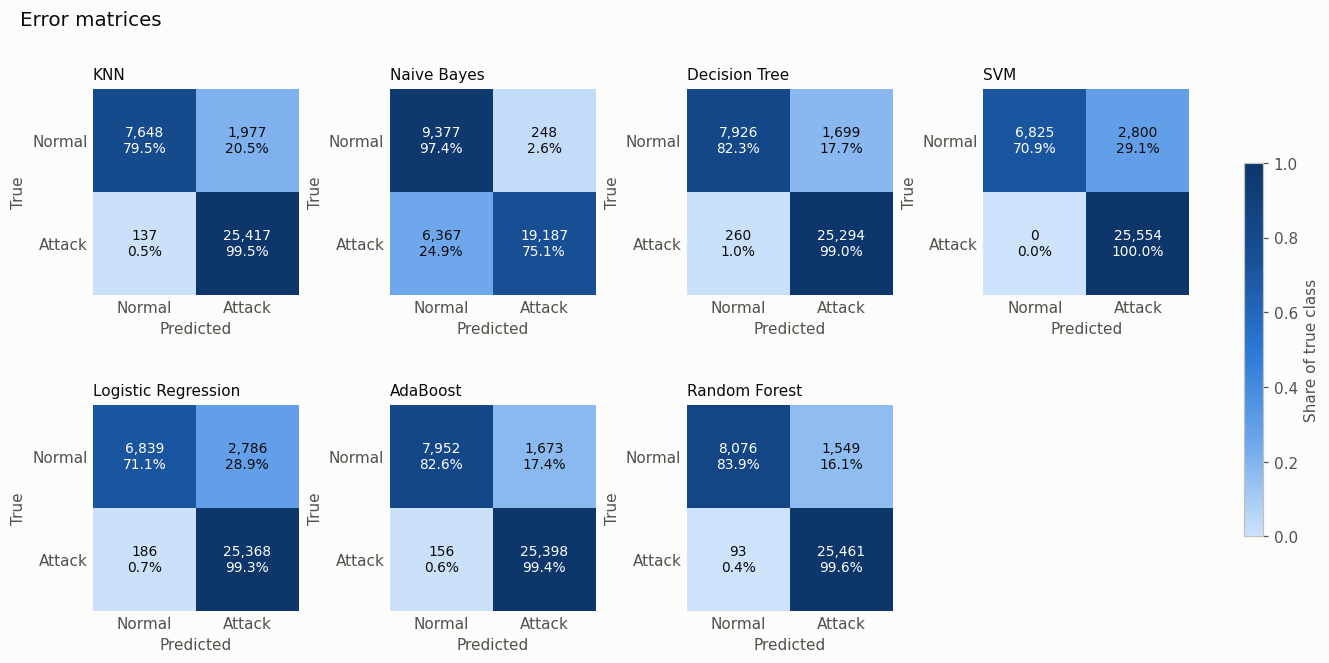

In [15]:
# Error matrices. Color and percentages are shares of each true class.
ramp = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
axes = axes.ravel()
image = None
for ax, name in zip(axes, MODEL_ORDER):
    row = results.loc[name]
    counts = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True)
    image = ax.imshow(shares, cmap=ramp, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(counts[i, j]):,}\n{100 * shares[i, j]:.1f}%", ha="center", va="center",
                    color="#ffffff" if shares[i, j] > 0.45 else INK, fontsize=9)
    ax.set_xticks([0, 1], ["Normal", "Attack"])
    ax.set_yticks([0, 1], ["Normal", "Attack"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(name, loc="left", fontsize=10)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[-1].set_visible(False)
fig.colorbar(image, ax=axes.tolist(), shrink=0.6, label="Share of true class")
fig.suptitle("Error matrices", x=0.01, ha="left", fontsize=13)
fig.savefig(OUT / "error_matrices.png")
plt.show()

## 6. Save your results

This creates a zip of all results and charts, then downloads it.


In [16]:
archive = shutil.make_archive("paper_method_results", "zip", OUT)
print("Created", archive)
from google.colab import files
files.download(archive)

Created /content/paper_method_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>